# Marketing Science Causal Inference Lab

This notebook uses the synthetic datasets created for the Marketing Science causal lab and implements:

1. A/B Testing
2. Difference-in-Differences (DiD)
3. Propensity Score Matching (PSM)
4. Inverse Probability Weighting (IPW)
5. Regression Discontinuity Design (RDD)
6. Instrumental Variables (IV / 2SLS)
7. Interrupted Time Series (ITS)
8. Synthetic Control
9. Causal Impact–style analysis
10. Uplift / CATE modeling
11. Marketing Mix Modeling (MMM)

The goal is not just to run code, but to make each method easy to explain in an interview.

> **Important:** columns beginning with `true_` are synthetic ground truth. Do **not** use them to estimate treatment effects. Use them only to validate your estimates afterward.

## 0. Setup

This notebook intentionally uses common Python packages: `pandas`, `numpy`, `scipy`, `statsmodels`, `scikit-learn`, and `matplotlib`.

If needed:

```bash
pip install pandas numpy scipy statsmodels scikit-learn matplotlib
```

In [36]:
# %pip uninstall statsmodels -y
# %pip install --no-cache-dir --force-reinstall statsmodels==0.14.6
import warnings
warnings.filterwarnings("ignore")

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from scipy.optimize import minimize

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest

from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [2]:
import statsmodels
print(statsmodels.__version__)

0.14.6


In [3]:
import numpy as np
import scipy
import pandas as pd
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.4.6
SciPy: 1.17.1
Pandas: 3.0.5


## 1. Load the datasets

In [4]:
DATA_DIR = Path("/mnt/data")

customer_week_path = DATA_DIR / "marketing_science_customer_week.csv"
market_week_path = DATA_DIR / "marketing_science_market_week.csv"

# Fallback to current working directory if you moved the notebook and CSVs together.
if not customer_week_path.exists():
    customer_week_path = Path("marketing_science_customer_week.csv")
if not market_week_path.exists():
    market_week_path = Path("marketing_science_market_week.csv")

cw = pd.read_csv(customer_week_path, parse_dates=["week_start"])
mw = pd.read_csv(market_week_path, parse_dates=["week_start"])

print("Customer-week shape:", cw.shape)
print("Market-week shape:", mw.shape)

display(cw.head())
display(mw.head())

Customer-week shape: (20800, 51)
Market-week shape: (624, 26)


,customer_id,week_start,week_index,month,quarter,market,region,age,income,tenure_months,prior_orders_90d,prior_revenue_90d,loyalty_member,mobile_app_user,email_opt_in,distance_to_store_km,is_did_treated_market,post_period,did_treatment,synthetic_control_target,causal_impact_target,iv_encouragement,observational_treatment,true_propensity,rdd_score,rdd_cutoff,rdd_running_variable,rdd_eligible,ab_assignment,lift_test_treatment,email_impressions,search_clicks,social_impressions,display_impressions,ctv_impressions,radio_grps,total_media_spend,discount_pct,price_index,competitor_price_index,holiday_flag,site_visits,conversion,orders,revenue,gross_margin,true_incremental_revenue,true_cate,uplift_segment,customer_acquisition_flag,churn_flag
0,C00001,2025-01-06,1,2025-01,2025-Q1,MKT_01,Northeast,44,"37,496.6600",52,5,120.8800,0,0,1,7.7400,0,0,0,0,0,1,1,0.3228,54.7900,50.0000,4.7900,1,0,0,0,1,4,0,3,6.6600,7.1100,0.2260,0.9590,0.9650,1,0,0,0,0.0000,0.0000,2.9200,3.0000,Medium,0,0
1,C00002,2025-01-06,1,2025-01,2025-Q1,MKT_02,Northeast,51,"58,543.9700",104,7,240.1100,0,0,0,2.5000,1,0,0,0,0,1,1,0.4658,64.6800,50.0000,14.6800,1,0,0,0,1,5,4,0,3.8200,4.7100,0.1180,0.9980,0.9790,1,0,0,0,0.0000,0.0000,3.1100,3.0000,Medium,0,0
2,C00003,2025-01-06,1,2025-01,2025-Q1,MKT_03,Northeast,30,"41,315.1100",68,7,265.8000,1,1,1,4.5800,0,0,0,0,0,0,1,0.6812,45.8400,50.0000,-4.1600,0,0,0,2,0,3,6,0,2.3200,1.9500,0.1240,0.9410,0.9730,1,4,1,1,34.2900,13.6500,1.6900,5.5000,High,0,0
3,C00004,2025-01-06,1,2025-01,2025-Q1,MKT_04,Midwest,37,"117,327.4000",81,7,197.4700,0,1,1,1.2200,0,0,0,0,0,1,1,0.6275,56.4600,50.0000,6.4600,1,0,0,1,0,7,1,0,4.5500,3.6200,0.1260,0.9440,1.0020,1,2,1,1,33.1500,12.4700,3.2100,5.5000,High,0,0
4,C00005,2025-01-06,1,2025-01,2025-Q1,MKT_05,Midwest,35,"64,301.8000",120,3,83.8400,0,1,1,3.7700,1,0,0,1,1,0,1,0.3055,58.6500,50.0000,8.6500,1,0,0,4,1,2,4,0,6.4300,6.6500,0.1930,0.9830,1.0030,1,3,1,1,40.4900,13.5400,3.1300,3.0000,Medium,0,0


,market,week_start,week_index,month,quarter,region,customers,orders,revenue,gross_margin,total_media_spend,email_impressions,search_clicks,social_impressions,display_impressions,ctv_impressions,radio_grps,did_treatment,post_period,synthetic_control_target,causal_impact_target,lift_test_treatment,holiday_flag,conversion_rate,revenue_per_customer,roas
0,MKT_01,2025-01-06,1,2025-01,2025-Q1,Northeast,34,13,408.3100,139.3100,179.6000,59,26,128,96,24,170.6900,0,0,0,0,0,1,0.3824,12.0100,2.2730
1,MKT_02,2025-01-06,1,2025-01,2025-Q1,Northeast,34,12,411.6200,145.5700,135.6300,55,23,114,86,22,119.7400,0,0,0,0,0,1,0.3529,12.1100,3.0350
2,MKT_03,2025-01-06,1,2025-01,2025-Q1,Northeast,34,17,554.0000,187.3800,135.7200,60,17,141,108,18,132.1800,0,0,0,0,0,1,0.5000,16.2900,4.0820
3,MKT_04,2025-01-06,1,2025-01,2025-Q1,Midwest,34,13,433.7700,151.1400,165.3400,53,23,155,92,26,157.2100,0,0,0,0,0,1,0.3824,12.7600,2.6240
4,MKT_05,2025-01-06,1,2025-01,2025-Q1,Midwest,33,15,476.1400,160.8500,144.3400,61,22,114,76,29,132.5800,0,0,1,1,0,1,0.4545,14.4300,3.2990


In [5]:
print("Customer-week missing values:", int(cw.isna().sum().sum()))
print("Market-week missing values:", int(mw.isna().sum().sum()))

print("\nWeeks:", cw["week_index"].min(), "to", cw["week_index"].max())
print("Markets:", sorted(cw["market"].unique()))
print("Customers:", cw["customer_id"].nunique())

Customer-week missing values: 0
Market-week missing values: 0

Weeks: 1 to 52
Markets: ['MKT_01', 'MKT_02', 'MKT_03', 'MKT_04', 'MKT_05', 'MKT_06', 'MKT_07', 'MKT_08', 'MKT_09', 'MKT_10', 'MKT_11', 'MKT_12']
Customers: 400


# 2. A/B Testing

### Business question
Does the randomized treatment increase conversion or revenue?

### Why this method works
Random assignment breaks the link between treatment and confounders. Therefore, the average outcome difference is an unbiased estimate of the Average Treatment Effect (ATE), subject to randomization and no-interference assumptions.

We restrict the analysis to markets where the experiment was randomized.

In [6]:
ab = cw[cw["market"].isin(["MKT_03", "MKT_04", "MKT_07", "MKT_08"])].copy()

ab_customer = (
    ab.groupby(["customer_id", "ab_assignment"], as_index=False)
      .agg(
          conversion_rate=("conversion", "mean"),
          revenue=("revenue", "sum"),
          orders=("orders", "sum")
      )
)

summary_ab = ab_customer.groupby("ab_assignment").agg(
    customers=("customer_id", "nunique"),
    conversion_rate=("conversion_rate", "mean"),
    mean_revenue=("revenue", "mean"),
    mean_orders=("orders", "mean")
)
display(summary_ab)

control = ab_customer.loc[ab_customer.ab_assignment == 0, "revenue"]
treat = ab_customer.loc[ab_customer.ab_assignment == 1, "revenue"]

ate_revenue = treat.mean() - control.mean()
t_stat, p_value = stats.ttest_ind(treat, control, equal_var=False)

print(f"ATE on annual customer revenue: ${ate_revenue:,.2f}")
print(f"Welch t-test p-value: {p_value:.4g}")

,customers,conversion_rate,mean_revenue,mean_orders
ab_assignment,,,,
0,58,0.3607,609.4579,19.8966
1,76,0.4734,808.7236,26.4474


ATE on annual customer revenue: $199.27
Welch t-test p-value: 6.052e-06


In [7]:
# Conversion-rate z-test at the customer-week level
successes = ab.groupby("ab_assignment")["conversion"].sum().reindex([0,1]).values
nobs = ab.groupby("ab_assignment")["conversion"].count().reindex([0,1]).values

z_stat, p_conv = proportions_ztest(successes, nobs)
control_rate = successes[0] / nobs[0]
treat_rate = successes[1] / nobs[1]

print(f"Control conversion: {control_rate:.3%}")
print(f"Treatment conversion: {treat_rate:.3%}")
print(f"Absolute lift: {(treat_rate-control_rate):.3%}")
print(f"Relative lift: {(treat_rate/control_rate-1):.2%}")
print(f"Conversion z-test p-value: {p_conv:.4g}")

Control conversion: 36.074%
Treatment conversion: 47.343%
Absolute lift: 11.269%
Relative lift: 31.24%
Conversion z-test p-value: 4.139e-21


“We randomized customers into treatment and control, compared conversion and revenue, and used a significance test plus confidence-oriented diagnostics. Because assignment is randomized, the treatment-control difference can be interpreted causally.”

# 3. Difference-in-Differences (DiD)

### Business question
##### Did the campaign change revenue in treated markets relative to control markets after launch?

### Core model

$$
Y_{it} = \beta_0 + \beta_1 \text{Treat}_i + \beta_2 \text{Post}_t + \beta_3(\text{Treat}_i \times \text{Post}_t) + \epsilon_{it}
$$

The coefficient \beta_3 is the DiD estimate.

### Difference-in-Differences Model Explanation

This is a **Difference-in-Differences (DiD) regression model**, used to estimate the causal impact of a treatment, such as a marketing campaign, by comparing changes over time between a **treatment group** and a **control group**.

$$
Y_{it} = \beta_0 + \beta_1 \text{Treat}_i + \beta_2 \text{Post}_t + \beta_3(\text{Treat}_i \times \text{Post}_t) + \epsilon_{it}
$$

Where:

- $Y_{it}$ is the outcome of interest, such as sales, revenue, or conversions.
- $\beta_0$ represents the baseline outcome for the control group before the treatment.
- $\beta_1$ captures the baseline difference between the treatment and control groups.
- $\beta_2$ captures the overall change after the intervention that affects both groups.
- $\beta_3$ is the **Difference-in-Differences treatment effect**. It measures the additional change experienced by the treatment group after the intervention, beyond the change observed in the control group.
- $\epsilon_{it}$ represents unexplained variation or random error.

The most important coefficient is **$\beta_3$**, because it estimates the causal effect of the treatment under the DiD assumptions.

$$
Revenue_{it} =
\beta_0
+ \beta_3 (Treatment_i \times Post_t)
+ MarketFE_i
+ WeekFE_t
+ \epsilon_{it}
$$

Here we are using **market and week fixed effects**, market as a categorical variable to control for persistent difference between markets and treatment_market, and weeks controls for things affecting all markets during a particular week.

In [37]:
did = mw.copy()

#Identify the treatment markets ( This creates a binary variable:MKT_x = 1, all other market =0)
did["treated_market"] = did["market"].isin(["MKT_02", "MKT_05", "MKT_09"]).astype(int)

#Identify the post-treatment period (weeks 1-26 ->post=0, week 27+ -> post =1)
did["post"] = (did["week_index"] >= 27).astype(int)

# Create the DiD interaction ( 1x0 = 0, 1*1 = 1, i.e post = 1 and treatment=1)
did["did_interaction"] = did["treated_market"] * did["post"]

# Simple DiD regression with market and week fixed effects.
did_model = smf.ols(
    "revenue ~ did_interaction + C(market) + C(week_index)",
    data=did
).fit(cov_type="cluster", cov_kwds={"groups": did["market"]}) # cluster the standard errs

print(did_model.summary().tables[1])
print("\nDiD estimate:", did_model.params["did_interaction"])

                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept             498.9792     27.542     18.117      0.000     444.997     552.961
C(market)[T.MKT_02]    -5.7657      9.184     -0.628      0.530     -23.767      12.235
C(market)[T.MKT_03]   101.3185   3.22e-13   3.15e+14      0.000     101.318     101.318
C(market)[T.MKT_04]   115.6698   7.88e-13   1.47e+14      0.000     115.670     115.670
C(market)[T.MKT_05]   -33.2888      9.184     -3.624      0.000     -51.290     -15.288
C(market)[T.MKT_06]    21.2365   5.41e-13   3.93e+13      0.000      21.237      21.237
C(market)[T.MKT_07]    61.2158   7.39e-13   8.29e+13      0.000      61.216      61.216
C(market)[T.MKT_08]    73.9235   6.87e-13   1.08e+14      0.000      73.923      73.923
C(market)[T.MKT_09]   -28.0842      9.184     -3.058      0.002     -46.085     -10.083
C(market)[T.MKT_10]   -35.3312  

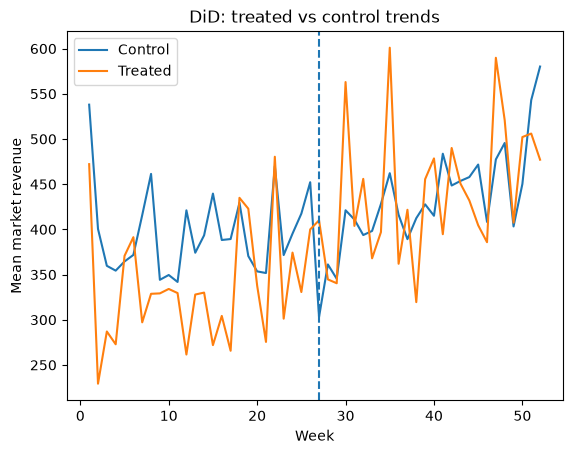

In [9]:
trend = (
    did.groupby(["week_index", "treated_market"], as_index=False)["revenue"].mean()
)

for flag, grp in trend.groupby("treated_market"):
    plt.plot(grp["week_index"], grp["revenue"], label="Treated" if flag else "Control")
plt.axvline(27, linestyle="--")
plt.xlabel("Week")
plt.ylabel("Mean market revenue")
plt.title("DiD: treated vs control trends")
plt.legend()
plt.show()

**Interview explanation:**  
“I compared the change in treated markets before versus after the campaign against the same change in untreated markets. The key validity check is whether pre-treatment trends are reasonably parallel.”

### Simple Method to calculate Difference-in-Differences.

You calculate the before-to-after revenue change for the treatment group, then subtract the before-to-after revenue change for the control group: **DiD=(Treatment After−Treatment Before)−(Control After−Control Before)**  

For example, suppose:

**Treatment revenue**:
Before = $100K,  After = $140K →  Change = +$40K  

**Control revenue**: 
Before = $90K, After = $110K → Change = +$20K    
Then: **DiD=40K−20K=20K**    

# 4. Propensity Score Matching (PSM)

Propensity Score Matching (PSM) is a causal inference technique used with observational data when a randomized A/B test is not possible. It tries to create comparable treatment and control groups by estimating each observation’s probability of receiving the treatment—the propensity score—based on characteristics such as demographics, past purchases, location, or customer behavior. This probability is commonly estimated using logistic regression.

For example, if we want to measure whether a marketing coupon increases sales, we can match customers who received the coupon with similar customers who did not receive it but had approximately the same propensity score. We then compare the outcomes, such as revenue, between the matched groups. The difference provides an estimate of the treatment effect. PSM helps reduce selection bias, but it can only account for observed characteristics included in the model.

**1. Calculate a propensity score**

Use pre-treatment characteristics to predict each customer's probability of receiving the coupon:

$$ P(Treatment=1|X) $$

For example:

$$ P(Coupon=1) = f(Age,\ PreviousOrders,\ PreviousSpend,\ Loyalty,\ Location) $$

Usually this is estimated with logistic regression, although other classifiers can be used.

$$ P(Treatment=1)=Logistic(β0​+β1​Age+β2​Income+β3​PriorOrders+...) $$

**2. Match similar customers**

Suppose:

| Customer | Coupon | Propensity Score |
|----------|--------|------------------|
| A        | Yes    | 0.78             |
| B        | No     | 0.76             |
| C        | Yes    | 0.42             |
| D        | No     | 0.44             |

You match A ↔ B and C ↔ D because their probabilities of receiving treatment are similar.

**3. Compare outcomes**

After matching:

$$ Treatment\ Effect = Average(Y_{treated} - Y_{matched\ control}) $$

If matched coupon customers spent \\$42  on average and matched non-coupon customers spent \\$35:

$$ ATT = 42 - 35 = \$7 $$

So you would estimate that the coupon generated approximately $7 additional spending per treated customer, subject to the assumptions of PSM.

### Business question
##### What is the treatment effect when treatment was not randomly assigned?

PSM estimates the probability of treatment from observed covariates, then matches treated customers to comparable untreated customers.

In [15]:
customer_level = (
    cw.sort_values("week_index")
      .groupby("customer_id", as_index=False)
      .agg(
          observational_treatment=("observational_treatment", "first"),
          age=("age", "first"),
          income=("income", "first"),
          tenure_months=("tenure_months", "first"),
          prior_orders_90d=("prior_orders_90d", "first"),
          prior_revenue_90d=("prior_revenue_90d", "first"),
          loyalty_member=("loyalty_member", "first"),
          mobile_app_user=("mobile_app_user", "first"),
          email_opt_in=("email_opt_in", "first"),
          distance_to_store_km=("distance_to_store_km", "first"),
          revenue=("revenue", "sum"),
          conversion_rate=("conversion", "mean"),
          true_propensity=("true_propensity", "first")
      )
)

features = [
    "age","income","tenure_months","prior_orders_90d","prior_revenue_90d",
    "loyalty_member","mobile_app_user","email_opt_in","distance_to_store_km"
]

X = customer_level[features]
y = customer_level["observational_treatment"]

scaler = StandardScaler() # z = (x- u)/sigma
Xs = scaler.fit_transform(X)

ps_model = LogisticRegression(max_iter=2000)
ps_model.fit(Xs, y)

calculates the estimated propensity score for every customer.
customer_level["ps_hat"] = ps_model.predict_proba(Xs)[:,1]

display(customer_level[["customer_id","observational_treatment","ps_hat","true_propensity"]].head())

,customer_id,observational_treatment,ps_hat,true_propensity
0,C00001,1,0.4970,0.3228
1,C00002,1,0.7453,0.4658
2,C00003,1,0.7393,0.6812
3,C00004,1,0.7401,0.6275
4,C00005,1,0.5513,0.3055


In [38]:
treated = customer_level[customer_level.observational_treatment == 1].copy()
control = customer_level[customer_level.observational_treatment == 0].copy()

nn = NearestNeighbors(n_neighbors=1) # find one control customer that is most similar based on propensity score
nn.fit(control[["ps_hat"]]) 

distances, indices = nn.kneighbors(treated[["ps_hat"]])
matched_control = control.iloc[indices.flatten()].reset_index(drop=True)
matched_treated = treated.reset_index(drop=True)

psm_ate = matched_treated["revenue"].mean() - matched_control["revenue"].mean()

print(f"Matched treated customers: {len(matched_treated)}")
print(f"PSM estimated treatment effect on annual revenue: ${psm_ate:,.2f}")
print(f"Mean propensity distance: {distances.mean():.4f}")

Matched treated customers: 236
PSM estimated treatment effect on annual revenue: $88.03
Mean propensity distance: 0.0035


**Interview explanation:**  
“I modeled treatment probability using only pre-treatment customer characteristics, matched treated customers to similar controls, then compared outcomes. PSM only removes bias from observed confounders, not unobserved ones.”

~Note: In a real-world PSM analysis, you normally do not have true_propensity. You only have the treatment assignment and customer characteristics, so you estimate the propensity score (ps_hat) and use that estimated score for matching. Your synthetic dataset includes true_propensity mainly so you can check how well your propensity model recovered the known treatment-assignment mechanism

# 5. Inverse Probability Weighting (IPW)

Inverse Probability Weighting (IPW) is a causal inference technique that uses the propensity score to make the treatment and control groups more comparable. Unlike PSM, which matches treated customers with similar control customers, IPW keeps all customers but gives each customer a weight based on how likely they were to receive the treatment they actually received.

Instead of matching, IPW creates a weighted pseudo-population where treatment is less associated with observed covariates.

For the Average Treatment Effect, ATE:

$$ 
w_i =
\begin{cases}
1/e(X_i), & T_i=1 \\
1/(1-e(X_i)), & T_i=0
\end{cases}
$$

In [40]:
eps = 1e-3
p = customer_level["ps_hat"].clip(eps, 1-eps)
t = customer_level["observational_treatment"]

customer_level["ipw"] = np.where(t == 1, 1/p, 1/(1-p))

treated_mean = np.average(
    customer_level.loc[t == 1, "revenue"],
    weights=customer_level.loc[t == 1, "ipw"]
)
control_mean = np.average(
    customer_level.loc[t == 0, "revenue"],
    weights=customer_level.loc[t == 0, "ipw"]
)

ipw_ate = treated_mean - control_mean

print(f"IPW treated mean revenue: ${treated_mean:,.2f}")
print(f"IPW control mean revenue: ${control_mean:,.2f}")
print(f"IPW ATE: ${ipw_ate:,.2f}")

IPW treated mean revenue: $671.59
IPW control mean revenue: $572.83
IPW ATE: $98.76


count   400.0000
mean      1.9910
std       0.7529
min       1.0641
25%       1.4775
50%       1.7822
75%       2.2933
max       7.6739
Name: ipw, dtype: float64


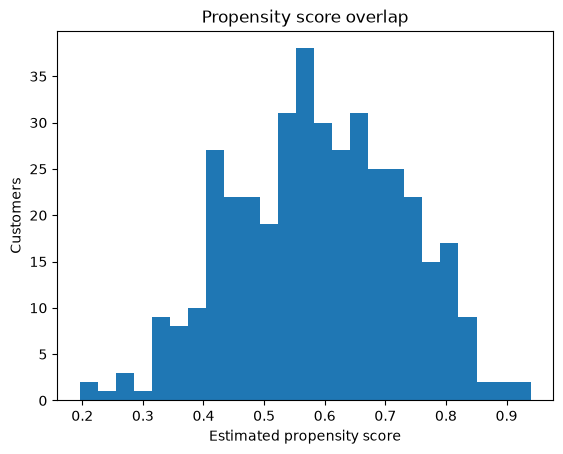

In [41]:
print(customer_level["ipw"].describe())

plt.hist(customer_level["ps_hat"], bins=25)
plt.xlabel("Estimated propensity score")
plt.ylabel("Customers")
plt.title("Propensity score overlap")
plt.show()

“IPW uses inverse treatment probabilities to reweight the sample so treated and untreated customers become more comparable. I always inspect overlap and extreme weights because positivity problems can make the estimator unstable.”

# 6. Regression Discontinuity Design (RDD)

### Business question
What is the local treatment effect for customers just above versus just below an eligibility cutoff?

The simulated cutoff is 50.

In [19]:
rdd_customer = (
    cw.groupby("customer_id", as_index=False)
      .agg(
          rdd_score=("rdd_score","first"),
          rdd_running_variable=("rdd_running_variable","first"),
          rdd_eligible=("rdd_eligible","first"),
          revenue=("revenue","sum")
      )
)

bandwidth = 12
local = rdd_customer[rdd_customer["rdd_running_variable"].abs() <= bandwidth].copy()

rdd_model = smf.ols(
    "revenue ~ rdd_eligible + rdd_running_variable + rdd_eligible:rdd_running_variable",
    data=local
).fit(cov_type="HC1")

print(rdd_model.summary().tables[1])
print("\nLocal RDD discontinuity estimate:", rdd_model.params["rdd_eligible"])

                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                           590.9438     40.498     14.592      0.000     511.568     670.319
rdd_eligible                         87.4707     58.438      1.497      0.134     -27.066     202.008
rdd_running_variable                 -4.1411      6.896     -0.600      0.548     -17.657       9.375
rdd_eligible:rdd_running_variable     0.9736      9.482      0.103      0.918     -17.610      19.557

Local RDD discontinuity estimate: 87.47073960251531


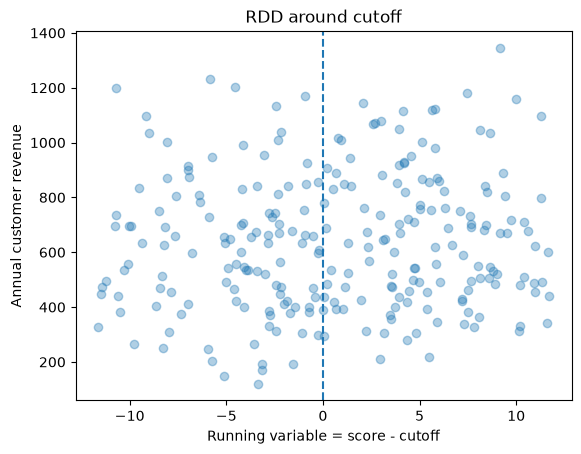

In [20]:
plt.scatter(local["rdd_running_variable"], local["revenue"], alpha=0.35)
plt.axvline(0, linestyle="--")
plt.xlabel("Running variable = score - cutoff")
plt.ylabel("Annual customer revenue")
plt.title("RDD around cutoff")
plt.show()

**Interview explanation:**  
“I restricted analysis to customers near the threshold and estimated whether the outcome jumps at the cutoff. RDD identifies a local treatment effect, not necessarily the effect for the entire population.”

# 7. Instrumental Variables (IV / 2SLS)

### Business question
How can we estimate treatment effect if observational treatment is confounded?

The synthetic dataset includes a randomized encouragement instrument.

### Two-stage least squares

1. Predict treatment from the instrument.
2. Regress outcome on predicted treatment.

In [21]:
iv_customer = (
    cw.groupby("customer_id", as_index=False)
      .agg(
          iv_encouragement=("iv_encouragement","first"),
          observational_treatment=("observational_treatment","first"),
          age=("age","first"),
          income=("income","first"),
          prior_orders_90d=("prior_orders_90d","first"),
          loyalty_member=("loyalty_member","first"),
          mobile_app_user=("mobile_app_user","first"),
          distance_to_store_km=("distance_to_store_km","first"),
          revenue=("revenue","sum")
      )
)

first_stage = smf.ols(
    "observational_treatment ~ iv_encouragement + age + income + prior_orders_90d + loyalty_member + mobile_app_user + distance_to_store_km",
    data=iv_customer
).fit(cov_type="HC1")

iv_customer["treatment_hat"] = first_stage.predict(iv_customer)

second_stage = smf.ols(
    "revenue ~ treatment_hat + age + income + prior_orders_90d + loyalty_member + mobile_app_user + distance_to_store_km",
    data=iv_customer
).fit(cov_type="HC1")

print("FIRST STAGE")
print(first_stage.summary().tables[1])

print("\nSECOND STAGE")
print(second_stage.summary().tables[1])

print("\nIV treatment estimate:", second_stage.params["treatment_hat"])

FIRST STAGE
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                0.1773      0.119      1.488      0.137      -0.056       0.411
iv_encouragement         0.2440      0.047      5.241      0.000       0.153       0.335
age                      0.0021      0.002      1.117      0.264      -0.002       0.006
income                8.495e-08   7.14e-07      0.119      0.905   -1.31e-06    1.48e-06
prior_orders_90d         0.0438      0.010      4.378      0.000       0.024       0.063
loyalty_member           0.0988      0.048      2.069      0.039       0.005       0.192
mobile_app_user          0.0598      0.048      1.244      0.213      -0.034       0.154
distance_to_store_km    -0.0184      0.008     -2.255      0.024      -0.034      -0.002

SECOND STAGE
                           coef    std err          z      P>|z|      [0.025      0.

In [22]:
fs_reduced = smf.ols(
    "observational_treatment ~ age + income + prior_orders_90d + loyalty_member + mobile_app_user + distance_to_store_km",
    data=iv_customer
).fit()

fs_full = smf.ols(
    "observational_treatment ~ iv_encouragement + age + income + prior_orders_90d + loyalty_member + mobile_app_user + distance_to_store_km",
    data=iv_customer
).fit()

f_test = fs_full.compare_f_test(fs_reduced)
print("Instrument first-stage F-test:", f_test)

Instrument first-stage F-test: (np.float64(27.67536658799257), np.float64(2.3661486350132138e-07), np.float64(1.0))


**Interview explanation:**  
“The instrument must affect treatment take-up, must not directly affect the outcome, and should be independent of the unobserved confounders. The resulting effect is generally interpreted as a local average treatment effect for compliers.”

# 8. Interrupted Time Series (ITS)

### Business question
Did an intervention create a level shift or trend change in an aggregate KPI?

The synthetic interruption occurs at week 31.

In [23]:
its = (
    mw.groupby("week_index", as_index=False)
      .agg(revenue=("revenue","sum"))
)

its["post"] = (its["week_index"] >= 31).astype(int)
its["time_after"] = np.where(its["week_index"] >= 31, its["week_index"] - 31 + 1, 0)

its_model = smf.ols(
    "revenue ~ week_index + post + time_after",
    data=its
).fit(cov_type="HAC", cov_kwds={"maxlags":4})

print(its_model.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   4532.2482    199.393     22.730      0.000    4141.445    4923.052
week_index     2.2321     10.249      0.218      0.828     -17.856      22.321
post         116.8019    185.449      0.630      0.529    -246.672     480.276
time_after    53.7491     16.365      3.284      0.001      21.673      85.825


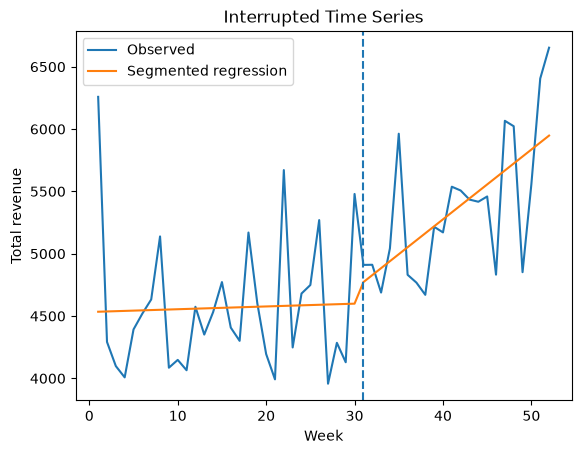

In [24]:
its["fitted"] = its_model.predict(its)

plt.plot(its["week_index"], its["revenue"], label="Observed")
plt.plot(its["week_index"], its["fitted"], label="Segmented regression")
plt.axvline(31, linestyle="--")
plt.xlabel("Week")
plt.ylabel("Total revenue")
plt.title("Interrupted Time Series")
plt.legend()
plt.show()

**Interview explanation:**  
“ITS models the pre-intervention trend, then estimates an immediate level change and a post-intervention slope change. The biggest risk is another event happening at the same time.”

# 9. Synthetic Control

### Business question
What would the treated market have done without treatment?

Synthetic Control forms a weighted combination of donor markets so that the weighted controls resemble the treated market before intervention.

In [25]:
sc = mw.pivot(index="week_index", columns="market", values="revenue").sort_index()

target_market = "MKT_05"
donor_markets = [c for c in sc.columns if c != target_market]

pre_mask = sc.index < 27
post_mask = sc.index >= 27

Y1_pre = sc.loc[pre_mask, target_market].values
Y0_pre = sc.loc[pre_mask, donor_markets].values

def objective(w):
    synth = Y0_pre @ w
    return np.mean((Y1_pre - synth)**2)

x0 = np.repeat(1/len(donor_markets), len(donor_markets))
bounds = [(0,1)] * len(donor_markets)
constraints = [{"type":"eq", "fun": lambda w: np.sum(w)-1}]

res = minimize(objective, x0, bounds=bounds, constraints=constraints)

weights = pd.Series(res.x, index=donor_markets).sort_values(ascending=False)
display(weights.to_frame("weight").head(10))

synthetic_series = sc[donor_markets].values @ res.x
sc_result = pd.DataFrame({
    "week_index": sc.index,
    "actual": sc[target_market].values,
    "synthetic": synthetic_series
})
sc_result["gap"] = sc_result["actual"] - sc_result["synthetic"]

post_effect_sc = sc_result.loc[sc_result.week_index >= 27, "gap"].mean()
print(f"Average post-treatment synthetic-control gap: ${post_effect_sc:,.2f} per week")

,weight
MKT_09,0.3516
MKT_06,0.2890
MKT_12,0.2076
MKT_02,0.0691
MKT_07,0.0567
MKT_11,0.0259
MKT_08,0.0000
MKT_10,0.0000
MKT_01,0.0000
MKT_04,0.0000


Average post-treatment synthetic-control gap: $2.54 per week


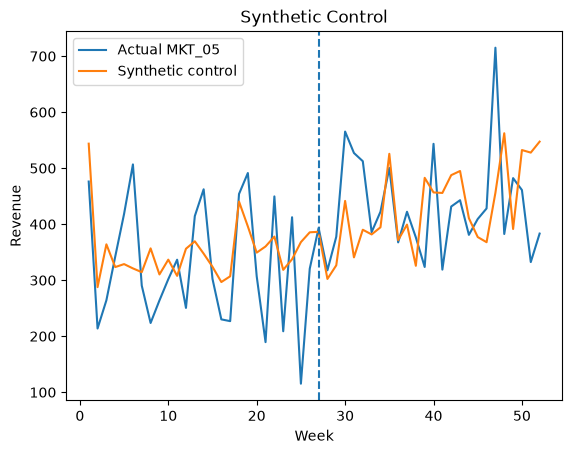

In [26]:
plt.plot(sc_result["week_index"], sc_result["actual"], label="Actual MKT_05")
plt.plot(sc_result["week_index"], sc_result["synthetic"], label="Synthetic control")
plt.axvline(27, linestyle="--")
plt.xlabel("Week")
plt.ylabel("Revenue")
plt.title("Synthetic Control")
plt.legend()
plt.show()

**Interview explanation:**  
“I optimized nonnegative donor-market weights that sum to one so the synthetic market closely matched the treated market before launch. After launch, the actual-minus-synthetic gap estimates the treatment effect.”

# 10. Causal Impact–style Analysis

Google's original CausalImpact uses Bayesian Structural Time Series. To keep this notebook dependency-light, we implement the same **counterfactual idea** using a pre-period regression on control markets plus seasonality terms.

This is ideal for explaining the logic in an interview:
- learn the pre-intervention relationship,
- forecast the untreated counterfactual,
- compare actual versus counterfactual after treatment.

In [27]:
ci_wide = mw.pivot(index="week_index", columns="market", values="revenue").sort_index()
target = "MKT_05"
controls = [c for c in ci_wide.columns if c != target]

ci_df = ci_wide.copy()
ci_df["sin13"] = np.sin(2*np.pi*ci_df.index/13)
ci_df["cos13"] = np.cos(2*np.pi*ci_df.index/13)

pre = ci_df.index < 27
post = ci_df.index >= 27

X_pre = sm.add_constant(ci_df.loc[pre, controls + ["sin13","cos13"]])
y_pre = ci_df.loc[pre, target]

ci_model = sm.OLS(y_pre, X_pre).fit()

X_all = sm.add_constant(ci_df[controls + ["sin13","cos13"]], has_constant="add")
pred = ci_model.get_prediction(X_all).summary_frame(alpha=0.05)

ci_result = pd.DataFrame({
    "week_index": ci_df.index,
    "actual": ci_df[target].values,
    "counterfactual": pred["mean"].values,
    "lower": pred["mean_ci_lower"].values,
    "upper": pred["mean_ci_upper"].values
})

ci_result["effect"] = ci_result["actual"] - ci_result["counterfactual"]

avg_effect_ci = ci_result.loc[ci_result.week_index >= 27, "effect"].mean()
cum_effect_ci = ci_result.loc[ci_result.week_index >= 27, "effect"].sum()

print(f"Average post effect: ${avg_effect_ci:,.2f}/week")
print(f"Cumulative post effect: ${cum_effect_ci:,.2f}")

Average post effect: $94.85/week
Cumulative post effect: $2,466.03


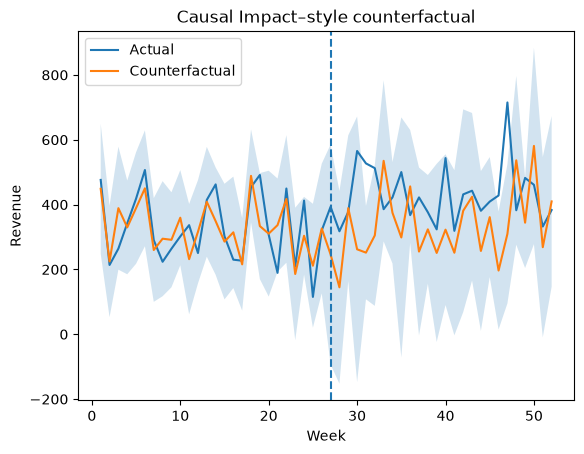

In [28]:
plt.plot(ci_result["week_index"], ci_result["actual"], label="Actual")
plt.plot(ci_result["week_index"], ci_result["counterfactual"], label="Counterfactual")
plt.fill_between(
    ci_result["week_index"],
    ci_result["lower"],
    ci_result["upper"],
    alpha=0.20
)
plt.axvline(27, linestyle="--")
plt.xlabel("Week")
plt.ylabel("Revenue")
plt.title("Causal Impact–style counterfactual")
plt.legend()
plt.show()

**Interview explanation:**  
“I trained a counterfactual model using only the pre-period and unaffected control markets, then projected what the treated market would have looked like without the intervention. The causal effect is the post-period difference between observed and predicted outcomes.”

# 11. Uplift / CATE Modeling

### Business question
Which customers should receive the campaign because they are most likely to respond incrementally?

We use a simple **T-learner**:
- fit one response model on treated customers,
- fit another on control customers,
- predicted uplift = predicted treatment outcome − predicted control outcome.

In [29]:
uplift_df = (
    cw[cw["market"].isin(["MKT_03","MKT_04","MKT_07","MKT_08"])]
    .groupby("customer_id", as_index=False)
    .agg(
        ab_assignment=("ab_assignment","first"),
        age=("age","first"),
        income=("income","first"),
        tenure_months=("tenure_months","first"),
        prior_orders_90d=("prior_orders_90d","first"),
        prior_revenue_90d=("prior_revenue_90d","first"),
        loyalty_member=("loyalty_member","first"),
        mobile_app_user=("mobile_app_user","first"),
        email_opt_in=("email_opt_in","first"),
        distance_to_store_km=("distance_to_store_km","first"),
        revenue=("revenue","sum"),
        true_cate=("true_cate","first"),
        uplift_segment=("uplift_segment","first")
    )
)

uplift_features = [
    "age","income","tenure_months","prior_orders_90d","prior_revenue_90d",
    "loyalty_member","mobile_app_user","email_opt_in","distance_to_store_km"
]

treated_u = uplift_df[uplift_df.ab_assignment == 1]
control_u = uplift_df[uplift_df.ab_assignment == 0]

model_t = RandomForestRegressor(n_estimators=300, min_samples_leaf=8, random_state=42)
model_c = RandomForestRegressor(n_estimators=300, min_samples_leaf=8, random_state=42)

model_t.fit(treated_u[uplift_features], treated_u["revenue"])
model_c.fit(control_u[uplift_features], control_u["revenue"])

uplift_df["pred_treated"] = model_t.predict(uplift_df[uplift_features])
uplift_df["pred_control"] = model_c.predict(uplift_df[uplift_features])
uplift_df["pred_uplift"] = uplift_df["pred_treated"] - uplift_df["pred_control"]

display(
    uplift_df.sort_values("pred_uplift", ascending=False)[
        ["customer_id","pred_uplift","uplift_segment","true_cate"]
    ].head(10)
)

,customer_id,pred_uplift,uplift_segment,true_cate
66,C00199,415.6393,High,5.5000
37,C00112,410.2484,High,5.5000
10,C00031,409.6751,Medium,3.0000
102,C00307,400.7957,Medium,3.0000
1,C00004,400.4303,High,5.5000
85,C00256,393.0017,Medium,3.0000
6,C00019,392.3204,High,5.5000
56,C00171,387.0514,Medium,3.0000
131,C00392,383.2527,Medium,3.0000
35,C00104,382.7479,Medium,3.0000


In [30]:
uplift_df["uplift_decile"] = pd.qcut(
    uplift_df["pred_uplift"].rank(method="first"),
    10,
    labels=False
) + 1

decile_summary = (
    uplift_df.groupby("uplift_decile", as_index=False)
    .agg(
        customers=("customer_id","count"),
        avg_pred_uplift=("pred_uplift","mean"),
        avg_true_cate=("true_cate","mean")
    )
    .sort_values("uplift_decile", ascending=False)
)

display(decile_summary)

,uplift_decile,customers,avg_pred_uplift,avg_true_cate
9,10,14,391.6030,3.8929
8,9,13,355.5507,3.9615
7,8,13,312.5878,3.0000
6,7,14,282.6142,3.3571
5,6,13,261.5869,3.3846
4,5,13,238.2232,3.3846
3,4,14,214.8951,3.0500
2,3,13,189.1780,3.8231
1,2,13,149.6204,1.8923
0,1,14,-30.2110,2.8714


**Interview explanation:**  
“Traditional propensity predicts who will buy. Uplift predicts who will buy **because of the treatment**. That distinction is critical for avoiding spend on customers who would have converted anyway.”

# 12. Marketing Mix Modeling (MMM)

### Business question
How much did each media channel contribute to revenue, after accounting for seasonality and business controls?

A production Bayesian MMM would typically add:
- adstock,
- saturation,
- priors,
- geo/time hierarchy,
- calibration to experiments.

Here we build a compact interview-friendly MMM using:
1. geometric adstock,
2. log saturation,
3. Ridge regression,
4. channel contribution approximation.

In [31]:
mmm = (
    mw.groupby("week_index", as_index=False)
      .agg(
          revenue=("revenue","sum"),
          email_impressions=("email_impressions","sum"),
          search_clicks=("search_clicks","sum"),
          social_impressions=("social_impressions","sum"),
          display_impressions=("display_impressions","sum"),
          ctv_impressions=("ctv_impressions","sum"),
          radio_grps=("radio_grps","sum"),
          holiday_flag=("holiday_flag","max")
      )
)

channel_cols = [
    "email_impressions","search_clicks","social_impressions",
    "display_impressions","ctv_impressions","radio_grps"
]

def geometric_adstock(x, alpha=0.5):
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    for i in range(len(x)):
        out[i] = x[i] + (alpha * out[i-1] if i > 0 else 0)
    return out

adstock_rates = {
    "email_impressions":0.25,
    "search_clicks":0.20,
    "social_impressions":0.45,
    "display_impressions":0.50,
    "ctv_impressions":0.65,
    "radio_grps":0.60
}

for c in channel_cols:
    mmm[c+"_adstock"] = geometric_adstock(mmm[c].values, adstock_rates[c])
    mmm[c+"_sat"] = np.log1p(mmm[c+"_adstock"])

mmm["trend"] = mmm["week_index"]
mmm["sin13"] = np.sin(2*np.pi*mmm["week_index"]/13)
mmm["cos13"] = np.cos(2*np.pi*mmm["week_index"]/13)
mmm["sin52"] = np.sin(2*np.pi*mmm["week_index"]/52)
mmm["cos52"] = np.cos(2*np.pi*mmm["week_index"]/52)

media_features = [c+"_sat" for c in channel_cols]
control_features = ["trend","sin13","cos13","sin52","cos52","holiday_flag"]
mmm_features = media_features + control_features

X = mmm[mmm_features]
y = mmm["revenue"]

x_scaler = StandardScaler()
Xz = x_scaler.fit_transform(X)

ridge = Ridge(alpha=10.0)
ridge.fit(Xz, y)

mmm["prediction"] = ridge.predict(Xz)

rmse = mean_squared_error(y, mmm["prediction"])**0.5
r2 = ridge.score(Xz, y)

print(f"MMM RMSE: ${rmse:,.2f}")
print(f"MMM R²: {r2:.3f}")

MMM RMSE: $316.98
MMM R²: 0.779


,standardized_coefficient
email_impressions_sat,34.9352
search_clicks_sat,3.5736
ctv_impressions_sat,-4.2688
radio_grps_sat,-22.2969
display_impressions_sat,-35.9040
social_impressions_sat,-56.8944


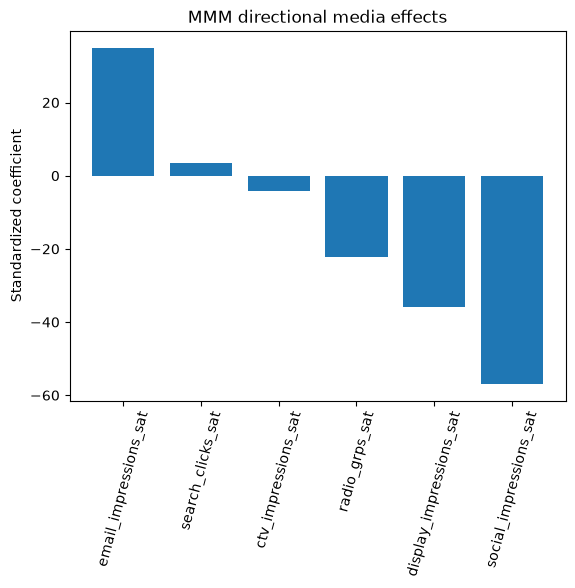

In [32]:
coef = pd.Series(ridge.coef_, index=mmm_features)
media_coef = coef[media_features].sort_values(ascending=False)
display(media_coef.to_frame("standardized_coefficient"))

plt.bar(media_coef.index, media_coef.values)
plt.xticks(rotation=75)
plt.ylabel("Standardized coefficient")
plt.title("MMM directional media effects")
plt.show()

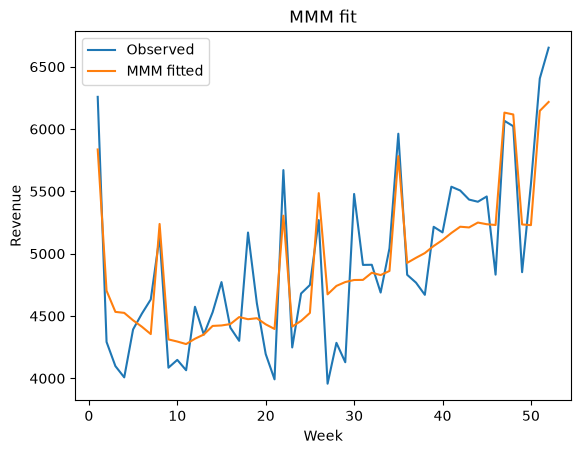

In [33]:
plt.plot(mmm["week_index"], mmm["revenue"], label="Observed")
plt.plot(mmm["week_index"], mmm["prediction"], label="MMM fitted")
plt.xlabel("Week")
plt.ylabel("Revenue")
plt.title("MMM fit")
plt.legend()
plt.show()

**Interview explanation:**  
“I first transformed channel activity for carryover using adstock and diminishing returns using a saturation transform. Then I modeled revenue as a function of transformed media plus trend, seasonality, and holidays. In production I would calibrate the model against experiments and use Bayesian priors to stabilize channel estimates.”

# 13. Compare the methods

These methods answer different causal questions:

| Method | Best use |
|---|---|
| A/B Test | Randomized customer-level experiment |
| DiD | Treated vs control groups before/after |
| PSM | Observational treatment with measured confounders |
| IPW | Observational treatment using propensity weighting |
| RDD | Eligibility/treatment changes at a cutoff |
| IV | Treatment is confounded but a valid instrument exists |
| ITS | One aggregate KPI before/after an intervention |
| Synthetic Control | One/few treated geographies with donor controls |
| Causal Impact | Time-series counterfactual using correlated controls |
| Uplift / CATE | Target customers based on incremental response |
| MMM | Estimate media contribution across channels over time |

# 14. Recommended interview framework

When asked **“How would you choose the methodology?”**, use this decision logic:

1. **Can I randomize?**  
   Use an A/B test or geo experiment.

2. **No randomization, but I have pre/post treatment and controls?**  
   Use DiD.

3. **Treatment is observational and I have rich customer covariates?**  
   Use PSM, IPW, or doubly robust methods.

4. **Treatment is determined by a threshold?**  
   Use RDD.

5. **I have a valid external source of treatment variation?**  
   Use IV.

6. **I have one treated time series and good comparison series?**  
   Use Causal Impact or Synthetic Control.

7. **I only have one long time series and a known intervention date?**  
   Use ITS.

8. **I want to know whom to target, not merely average lift?**  
   Use uplift / CATE modeling.

9. **I want portfolio-level media allocation across many channels?**  
   Use MMM, ideally calibrated with experiments.